# Olist E-Commerce Analysis: Sales, Delivery & Customer Satisfaction

**Author:** Wahyu Nur Agustusanto &nbsp;·&nbsp; **Tools:** SQL (SQLite), Python (pandas, matplotlib, scikit-learn)

**Objective.** Understand what drives revenue and customer satisfaction on Olist, a Brazilian online marketplace,
and find where operations can improve.

**Data.** [Olist public dataset](https://github.com/olist/work-at-olist-data): ~99k orders across 8 related tables
(orders, items, payments, reviews, customers, sellers, products, categories). The analysis window is
**Jan 2017 – Aug 2018** (99,092 orders); the months outside it have fewer than 1,000 orders and are incomplete.
Cleaning steps are documented in `reports/data_cleaning_log.md`, and every query lives in `sql/analysis.sql`.

**Business questions**
1. How are revenue and orders trending?
2. Which product categories drive revenue?
3. Does late delivery hurt customer satisfaction?
4. Which regions get the worst delivery service?
5. How do customers pay, and do installments raise basket size?
6. Do customers come back for a second order?
7. Can we flag orders likely to receive a negative review, so customer service can act first?

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path("..", "src").resolve()))
from queries import connect, run_query

FIG_DIR = Path("..", "reports", "figures").resolve()
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Chart style: one accent color for the story, gray for context, hairline grid
BLUE, GRAY = "#2a78d6", "#c3c2b7"
INK, INK_2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRAY, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10,
    "lines.linewidth": 2, "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
})
pd.set_option("display.float_format", "{:,.2f}".format)

conn = connect()

## 1. Data quality checks

Before trusting any number, check that the joins and the cleaning behaved as expected.

In [2]:
run_query("data_quality_checks", conn)

,check_name,value
0,orders in analysis window,99092
1,orders without items,739
2,orders without payment,2
3,orders without review,762
4,delivered orders without delivery date,8
5,orders where payment differs from price+freigh...,307


In [3]:
# Which orders have no items? (should be orders that were never fulfilled)
pd.read_sql_query(
    "SELECT status, COUNT(*) AS orders FROM fact_orders WHERE items_count IS NULL GROUP BY status", conn
)

,status,orders
0,canceled,132
1,created,5
2,unavailable,602


- The **739 orders without items** are all canceled, unavailable, or stuck in `created`, i.e. never fulfilled.
  They are excluded from revenue.
- The **307 orders (0.3%)** where payment differs from price + freight are mostly credit-card orders where the
  customer paid more than the list price (installment interest). Too small to affect the results; left as is.
- **762 orders have no review**; review-based metrics only use orders that have one.

## 2. Headline KPIs

In [4]:
kpis = run_query("overall_kpis", conn)
kpis.T.rename(columns={0: "value"})

,value
orders,"97,910.00"
customers,"94,707.00"
revenue,"13,449,530.00"
avg_order_value,137.37
late_delivery_pct,6.80
avg_delivery_days,12.50
avg_review_score,4.12


Over 20 months Olist sold **R$13.4M** across **97.9k orders** from **94.7k customers**.
The average order is **R$137**, delivery takes **12.5 days** on average, **6.8%** of orders arrive late,
and the average review is **4.12 / 5**.

## 3. Revenue trend and delivery performance over time

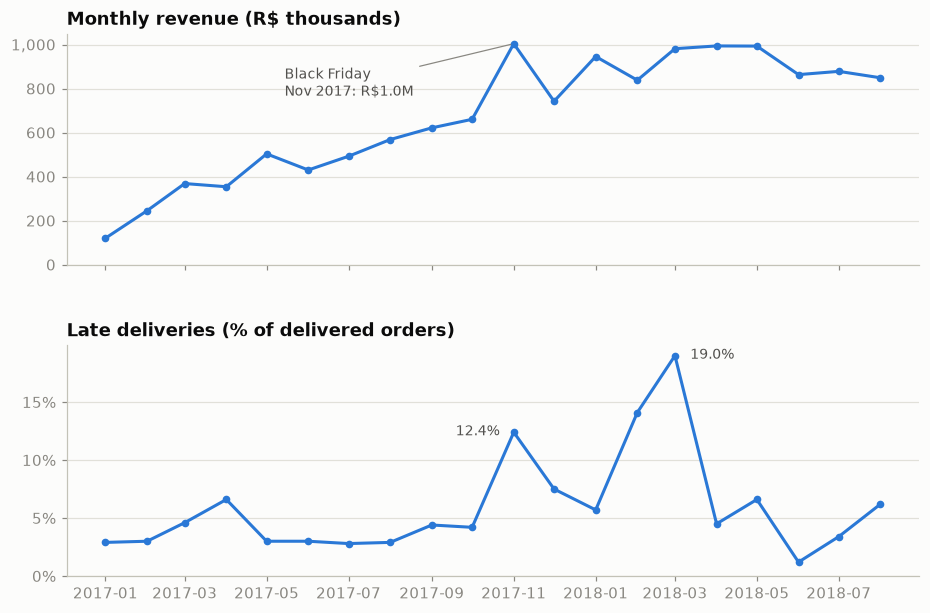

In [5]:
monthly = run_query("monthly_trend", conn)
delivery = run_query("monthly_delivery", conn)
monthly["month"] = pd.to_datetime(monthly["month"])
delivery["month"] = pd.to_datetime(delivery["month"])

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6.4), sharex=True, gridspec_kw={"hspace": 0.35})

ax1.plot(monthly["month"], monthly["revenue"] / 1e3, color=BLUE, marker="o", markersize=4)
ax1.set_title("Monthly revenue (R$ thousands)")
ax1.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
nov = monthly.loc[monthly["month"] == "2017-11-01"].iloc[0]
ax1.annotate("Black Friday\nNov 2017: R$1.0M", (nov["month"], nov["revenue"] / 1e3),
             xytext=(-150, -34), textcoords="offset points", color=INK_2, fontsize=9,
             arrowprops={"arrowstyle": "-", "color": MUTED, "lw": 0.8})

ax2.plot(delivery["month"], delivery["late_delivery_pct"], color=BLUE, marker="o", markersize=4)
ax2.set_title("Late deliveries (% of delivered orders)")
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
for m, label, dx in [("2017-11-01", "12.4%", -38), ("2018-03-01", "19.0%", 10)]:
    row = delivery.loc[delivery["month"] == m].iloc[0]
    ax2.annotate(label, (row["month"], row["late_delivery_pct"]), xytext=(dx, -2),
                 textcoords="offset points", color=INK_2, fontsize=9)

for ax in (ax1, ax2):
    ax.grid(axis="x", visible=False)
    ax.set_ylim(bottom=0)
fig.savefig(FIG_DIR / "01_revenue_trend.png")
plt.show()

In [6]:
jan_aug = lambda year: monthly.loc[(monthly["month"] >= f"{year}-01-01") & (monthly["month"] <= f"{year}-08-01"), "revenue"].sum()
print(f"Revenue Jan-Aug 2017: R${jan_aug(2017):,.0f}")
print(f"Revenue Jan-Aug 2018: R${jan_aug(2018):,.0f}  ({jan_aug(2018) / jan_aug(2017) - 1:+.0%} year over year)")

Revenue Jan-Aug 2017: R$3,080,850
Revenue Jan-Aug 2018: R$7,341,037  (+138% year over year)


**Findings**
- Revenue grew fast: **Jan–Aug 2018 was +138% vs Jan–Aug 2017**. Growth flattened in 2018 at about
  R$0.85–1.0M per month.
- **Black Friday (Nov 2017)** was the biggest month: 7,423 orders, +52% vs October.
- Logistics did not keep up with the peaks. Late deliveries jumped to **12.4% in Nov 2017** and
  **19.0% in Mar 2018**, against 3–5% in a normal month. From Apr 2018 the late rate dropped back to 1–7%.
- *Caveat:* the data ends in Oct 2018, so slow orders bought in Aug 2018 may not be delivered yet. Delivery
  times for the last months look slightly better than they really are.

## 4. Which categories drive revenue?

18 of 74 categories make up 80% of revenue; the top 10 make up 62%.


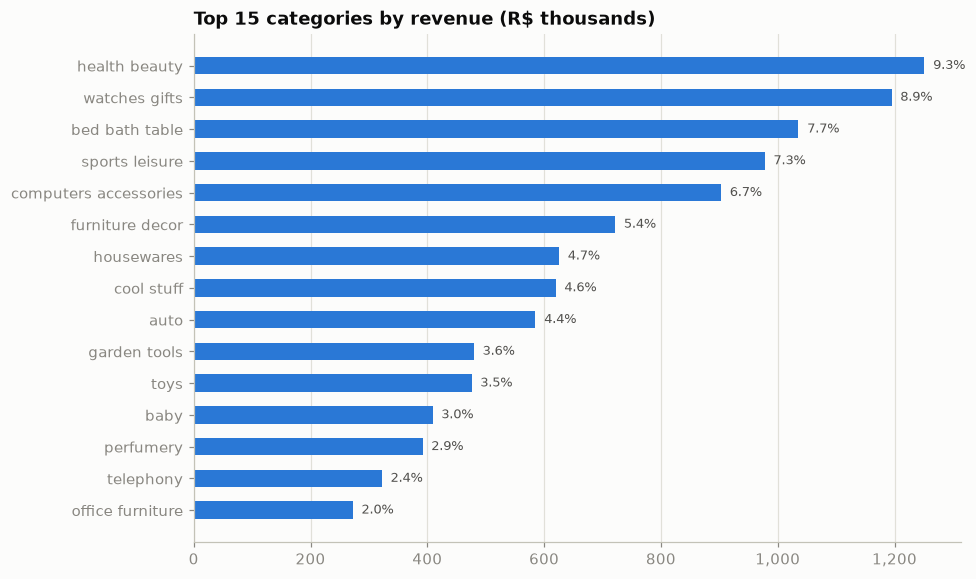

,category,orders,revenue,avg_item_price,share_pct,cumulative_pct
0,health_beauty,8757,"1,251,146.00",130.53,9.30,9.30
1,watches_gifts,5599,"1,194,825.00",200.31,8.90,18.20
2,bed_bath_table,9394,"1,035,485.00",93.38,7.70,25.90
3,sports_leisure,7656,"977,729.00",114.05,7.30,33.20
4,computers_accessories,6636,"902,923.00",116.36,6.70,39.90
5,furniture_decor,6373,"721,584.00",87.69,5.40,45.20
6,housewares,5838,"625,539.00",90.62,4.70,49.90
7,cool_stuff,3609,"619,724.00",164.30,4.60,54.50
8,auto,3863,"585,177.00",139.49,4.40,58.80
9,garden_tools,3500,"479,650.00",110.95,3.60,62.40


In [7]:
categories = run_query("top_categories", conn)
n_80 = int((categories["cumulative_pct"] < 80).sum() + 1)
print(f"{n_80} of {len(categories)} categories make up 80% of revenue; the top 10 make up "
      f"{categories['cumulative_pct'].iloc[9]:.0f}%.")

top = categories.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top["category"].str.replace("_", " "), top["revenue"] / 1e3, color=BLUE, height=0.55)
ax.set_title("Top 15 categories by revenue (R$ thousands)")
ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
for y, (rev, share) in enumerate(zip(top["revenue"] / 1e3, top["share_pct"])):
    ax.text(rev + 15, y, f"{share:.1f}%", va="center", fontsize=8.5, color=INK_2)
fig.savefig(FIG_DIR / "02_categories.png")
plt.show()

categories.head(10)

**Findings**
- Revenue is concentrated: **18 of 74 categories bring 80% of revenue**, and the top 10 bring 62%.
- **Health & beauty** and **watches & gifts** lead, but in different ways. Watches & gifts earns its revenue
  through price (avg item R$200), while bed/bath/table has the most orders but a low price (R$93).

## 5. Does late delivery hurt customer satisfaction?

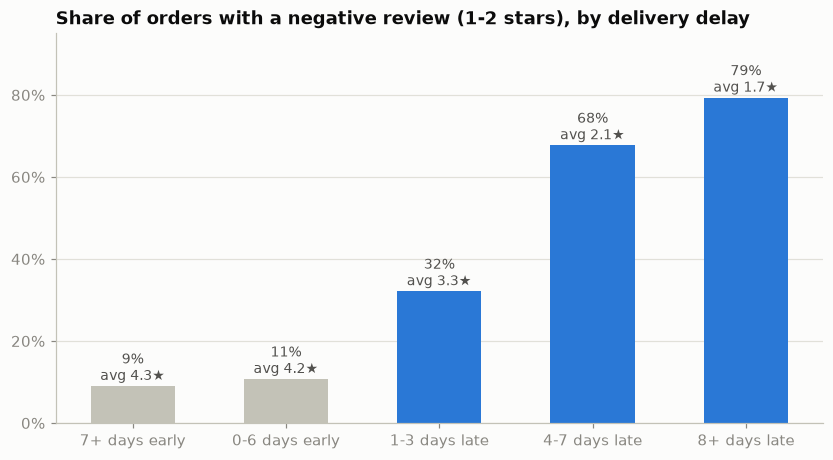

,delay_bucket,orders,avg_review_score,negative_review_pct
0,1. 7+ days early,75487,4.31,9.00
1,2. 0-6 days early,13695,4.17,10.70
2,3. 1-3 days late,1851,3.29,32.10
3,4. 4-7 days late,1748,2.10,67.70
4,5. 8+ days late,2779,1.70,79.30


In [8]:
delay = run_query("late_delivery_vs_review", conn)
labels = delay["delay_bucket"].str[3:]
colors = [GRAY, GRAY, BLUE, BLUE, BLUE]

fig, ax = plt.subplots(figsize=(9, 4.6))
bars = ax.bar(labels, delay["negative_review_pct"], color=colors, width=0.55)
ax.set_title("Share of orders with a negative review (1-2 stars), by delivery delay")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.grid(axis="x", visible=False)
for bar, pct, score in zip(bars, delay["negative_review_pct"], delay["avg_review_score"]):
    ax.text(bar.get_x() + bar.get_width() / 2, pct + 1.5, f"{pct:.0f}%\navg {score:.1f}★",
            ha="center", fontsize=9, color=INK_2)
ax.set_ylim(0, 95)
fig.savefig(FIG_DIR / "03_delay_vs_review.png")
plt.show()

delay

In [9]:
late_share = pd.read_sql_query(
    """SELECT ROUND(100.0 * SUM(is_late) / COUNT(*), 1) AS pct
       FROM fact_orders
       WHERE status = 'delivered' AND is_late IS NOT NULL AND review_score <= 2""", conn
).iloc[0, 0]
print(f"Late orders are 6.8% of deliveries but {late_share}% of all negative reviews.")

Late orders are 6.8% of deliveries but 32.6% of all negative reviews.


**Findings: this is the strongest signal in the data.**
- Orders delivered early or on time average **4.3★** and only 9–11% get a negative review.
- Once an order is late, satisfaction collapses: **1–3 days late → 32% negative**,
  **8+ days late → 79% negative (avg 1.7★)**.
- Late orders are only 6.8% of deliveries but cause **about a third of all negative reviews**.

## 6. Which regions get the worst delivery service?

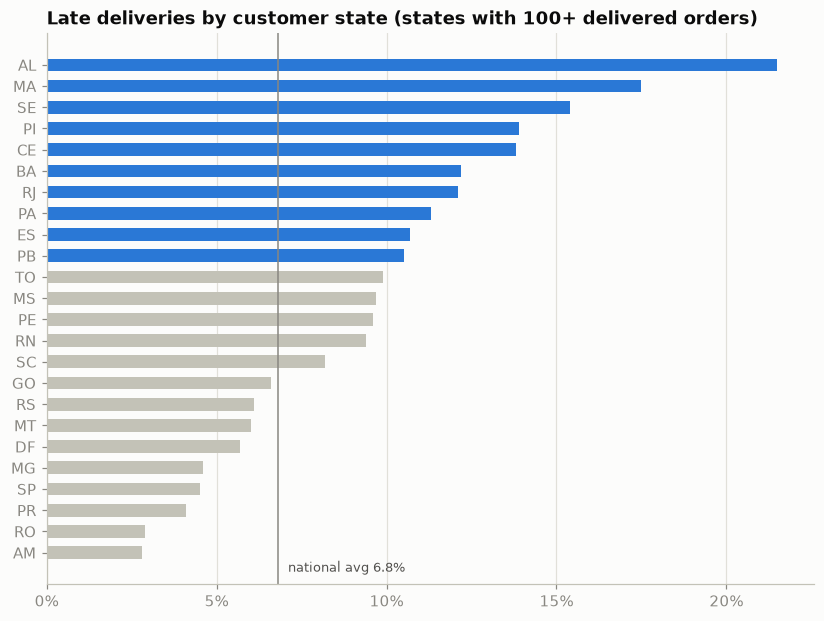

,customer_state,delivered_orders,avg_delivery_days,late_delivery_pct,freight_to_price_pct,avg_review_score
0,AL,396,24.50,21.50,19.60,3.85
1,MA,713,21.50,17.50,26.20,3.83
2,SE,332,21.40,15.40,24.30,3.90
3,PI,475,19.40,13.90,24.20,3.99
4,CE,1273,21.20,13.80,21.40,3.94
5,BA,3253,19.30,12.20,19.80,3.93
6,RJ,12310,15.30,12.10,16.90,3.97
7,PA,942,23.80,11.30,21.50,3.91


In [10]:
states = run_query("delivery_by_state", conn).sort_values("late_delivery_pct")
national = kpis.loc[0, "late_delivery_pct"]

fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(states["customer_state"], states["late_delivery_pct"],
        color=[BLUE if v > 10 else GRAY for v in states["late_delivery_pct"]], height=0.6)
ax.axvline(national, color=MUTED, lw=1)
ax.text(national + 0.3, -0.9, f"national avg {national}%", fontsize=8.5, color=INK_2)
ax.set_title("Late deliveries by customer state (states with 100+ delivered orders)")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.grid(axis="y", visible=False)
fig.savefig(FIG_DIR / "04_late_by_state.png")
plt.show()

states.sort_values("late_delivery_pct", ascending=False).head(8)

**Findings**
- **São Paulo (SP)**, 42% of delivered orders, is served well: 8.7 days, 4.5% late.
- The **North-East** is underserved. Alagoas (21.5% late), Maranhão (17.5%) and Sergipe (15.4%) wait 21–25 days
  and pay freight worth 20–26% of the item price (vs 14% in SP). Their reviews average below 3.9★.
- **Rio de Janeiro (RJ)** is the biggest operational problem: 12.1% late on 12,310 orders = **1,495 late orders**,
  almost as many as SP (1,817) with only a third of SP's volume.

## 7. How do customers pay?

,payment_type,orders,share_pct,avg_payment_value,avg_installments
0,credit_card,73891,75.50,166.59,3.60
1,boleto,19479,19.90,144.65,1.00
2,voucher,3028,3.10,114.93,1.10
3,debit_card,1512,1.50,140.29,1.00


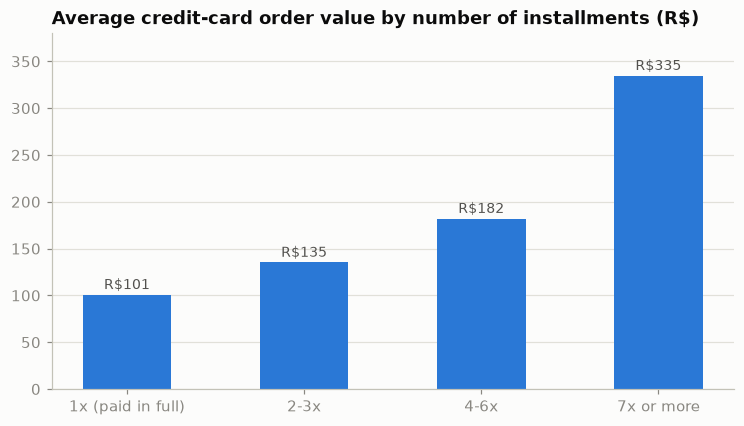

In [11]:
display(run_query("payment_mix", conn))

inst = run_query("installments_vs_value", conn)
fig, ax = plt.subplots(figsize=(8, 4.2))
bars = ax.bar(inst["installment_group"].str[3:], inst["avg_payment_value"], color=BLUE, width=0.5)
ax.set_title("Average credit-card order value by number of installments (R$)")
ax.grid(axis="x", visible=False)
for bar, v in zip(bars, inst["avg_payment_value"]):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 6, f"R${v:,.0f}", ha="center", fontsize=9, color=INK_2)
ax.set_ylim(0, 380)
fig.savefig(FIG_DIR / "05_installments.png")
plt.show()

**Findings**
- **Credit card is 75.5% of orders** (avg 3.6 installments), followed by boleto (bank slip) at 19.9%.
- Installments go hand in hand with bigger baskets: orders split into **7+ installments average R$335**,
  3.3× the R$101 of orders paid in full. (This is a correlation; expensive items are also the ones people
  split.)

## 8. Do customers come back?

In [12]:
run_query("customer_retention", conn)

,customers,repeat_customers,repeat_rate_pct,orders_per_customer
0,94707,2875,3.04,1.03


**Finding:** only **3.0% of customers placed a second order** in 20 months. Growth depends almost entirely on
acquiring new customers. This is an opportunity for retention campaigns (e.g. a voucher sent right after a
good delivery experience).

## 9. Predicting negative reviews

**Use case.** When an order is delivered we already know how long it took and whether it was late. If we can
score each delivered order for "risk of a 1–2★ review", customer service can contact the riskiest customers
first, before the review is written.

**Setup.** Delivered orders with a review (95.6k). Target = review of 1–2★ (12.8% of orders).
Features are all known at delivery time. Logistic regression (simple and explainable), balanced class
weights, 75/25 stratified train/test split.

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

orders = pd.read_sql_query(
    """SELECT * FROM fact_orders
       WHERE status = 'delivered' AND review_score IS NOT NULL AND delay_days IS NOT NULL""", conn
)
orders["negative_review"] = (orders["review_score"] <= 2).astype(int)
orders["multi_seller"] = (orders["sellers_count"] > 1).astype(int)
orders["log_order_value"] = np.log1p(orders["items_value"])
orders["freight_ratio"] = orders["freight_value"] / orders["items_value"]

features = ["delivery_days", "delay_days", "promised_days", "items_count",
            "multi_seller", "log_order_value", "freight_ratio", "installments"]
X, y = orders[features], orders["negative_review"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

model = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000))
model.fit(X_train, y_train)
risk = model.predict_proba(X_test)[:, 1]

print(f"Negative-review rate: {y.mean():.1%}")
print(f"ROC AUC, model:                {roc_auc_score(y_test, risk):.3f}")
print(f"ROC AUC, 'was it late?' only:  {roc_auc_score(y_test, orders.loc[X_test.index, 'is_late']):.3f}")
print()
print(classification_report(y_test, model.predict(X_test), digits=3))

Negative-review rate: 12.8%
ROC AUC, model:                0.743
ROC AUC, 'was it late?' only:  0.650

              precision    recall  f1-score   support

           0      0.929     0.798     0.858     20833
           1      0.298     0.586     0.395      3057

    accuracy                          0.771     23890
   macro avg      0.614     0.692     0.627     23890
weighted avg      0.848     0.771     0.799     23890



Top 10% riskiest orders: 51% actually got a negative review (base rate 13%), capturing 40% of all negative reviews.
multi_seller
single seller   0.12
multi seller    0.47
Name: negative_review, dtype: float64


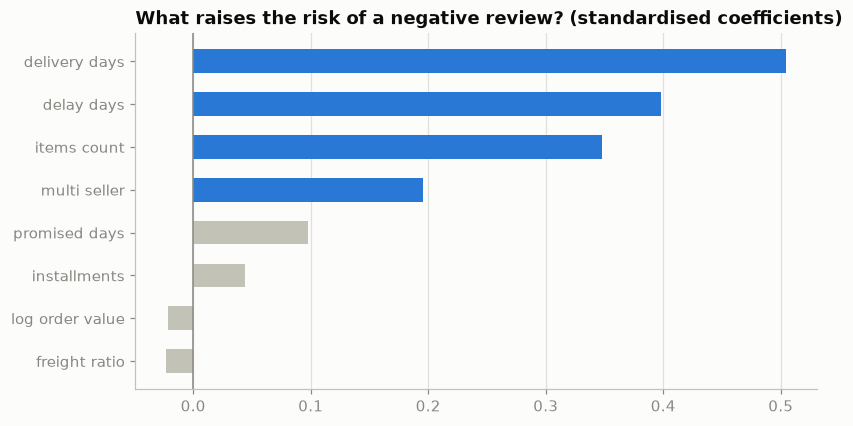

In [14]:
# How useful is the score in practice? Look at the 10% riskiest orders.
scored = pd.DataFrame({"negative": y_test, "risk": risk}).sort_values("risk", ascending=False)
top10 = scored.head(len(scored) // 10)
print(f"Top 10% riskiest orders: {top10['negative'].mean():.0%} actually got a negative review "
      f"(base rate {y.mean():.0%}), capturing {top10['negative'].sum() / scored['negative'].sum():.0%} "
      "of all negative reviews.")

print(orders.groupby("multi_seller")["negative_review"].mean().rename({0: "single seller", 1: "multi seller"}))

coef = pd.Series(model[-1].coef_[0], index=features).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(coef.index.str.replace("_", " "), coef.values, color=[BLUE if c > 0.1 else GRAY for c in coef.values],
        height=0.55)
ax.axvline(0, color=MUTED, lw=1)
ax.set_title("What raises the risk of a negative review? (standardised coefficients)")
ax.grid(axis="y", visible=False)
fig.savefig(FIG_DIR / "06_model.png")
plt.show()

**Findings**
- The model reaches **ROC AUC 0.74**, clearly better than using "was it late?" alone (0.65).
- In practice: the **10% riskiest orders** have a **51% negative-review rate** (4× the 13% base rate), and
  contacting them would reach **40% of all unhappy customers** while calling only 1 in 10.
- Strongest drivers: **long delivery time**, **delay vs the promised date**, **number of items**, and
  **orders from several sellers** (47% negative vs 12% for single-seller orders, likely because items arrive
  in separate packages and the order looks incomplete).
- *Limitations:* product quality, seller behaviour, and review text are not in the model, so it can only explain
  part of customer dissatisfaction. Next step: add seller history and simple NLP on review comments.

## 10. Key findings & recommendations

| # | Finding | Recommendation |
|---|---------|----------------|
| 1 | Late delivery is the strongest driver of bad reviews (79% negative when 8+ days late) | Track the weekly late-delivery rate as a core KPI, with an alert above 8% |
| 2 | Late rate spikes after demand peaks (12% Black Friday, 19% Mar 2018) | Plan carrier capacity before November and Q1; widen promised delivery dates during peaks |
| 3 | North-East states wait 21–25 days and pay 20–26% freight; RJ has ~1,500 late orders | Add carrier partners or a regional hub for the North-East; investigate the RJ last-mile carrier |
| 4 | Multi-seller orders get 47% negative reviews | Tell customers up front that items ship separately; send one tracking view per order |
| 5 | Installments go with 3.3× larger baskets | Promote interest-free installments on high-ticket categories (watches, computers) |
| 6 | Only 3% of customers buy again | Post-delivery voucher campaign, timed after on-time deliveries |
| 7 | A simple risk score finds 40% of unhappy customers in 10% of orders | Use the score to prioritise proactive customer-service contact |